# Parkinson's Disease Prediction
## End-to-End Machine Learning Project¶
### Objective: Build and evaluate classification models to predict Parkinson's disease status from biomedical voice measurements.

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn import metrics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score, cohen_kappa_score
import os
# Also ensure RANDOM_STATE is defined, e.g.:
RANDOM_STATE = 42

# 1. Data Loading

In [3]:
DATA_PATH = "parkinsons.data"  # Update path if required
df = pd.read_csv('parkinsons.data')
df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [4]:
# Read Data, display records

display (df)

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,phon_R01_S50_2,174.188,230.978,94.261,0.00459,0.00003,0.00263,0.00259,0.00790,0.04087,...,0.07008,0.02764,19.517,0,0.448439,0.657899,-6.538586,0.121952,2.657476,0.133050
191,phon_R01_S50_3,209.516,253.017,89.488,0.00564,0.00003,0.00331,0.00292,0.00994,0.02751,...,0.04812,0.01810,19.147,0,0.431674,0.683244,-6.195325,0.129303,2.784312,0.168895
192,phon_R01_S50_4,174.688,240.005,74.287,0.01360,0.00008,0.00624,0.00564,0.01873,0.02308,...,0.03804,0.10715,17.883,0,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728
193,phon_R01_S50_5,198.764,396.961,74.904,0.00740,0.00004,0.00370,0.00390,0.01109,0.02296,...,0.03794,0.07223,19.020,0,0.451221,0.643956,-6.744577,0.207454,2.138608,0.123306


# 2. Dataset Understanding and Data Quality Checks

### 🔎 Observations & Insights
- The dataset contains 195 observations and 24 columns, indicating a relatively small dataset. Model performance should therefore be interpreted carefully.
- The data consists mainly of numerical biomedical measurements, so categorical encoding is not required for the predictor variables.
- All columns should be checked for missing values and duplicates before modelling.
- Because the dataset is small, future versions should use Stratified Cross-Validation to obtain more reliable performance estimates.

In [5]:
print("Dataset shape:", df.shape)
print("\nData types:")
display(df.dtypes)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
display(df.describe().T)
print("\nMissing values:")
display(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (195, 24)

Data types:


name                 object
MDVP:Fo(Hz)         float64
MDVP:Fhi(Hz)        float64
MDVP:Flo(Hz)        float64
MDVP:Jitter(%)      float64
MDVP:Jitter(Abs)    float64
MDVP:RAP            float64
MDVP:PPQ            float64
Jitter:DDP          float64
MDVP:Shimmer        float64
MDVP:Shimmer(dB)    float64
Shimmer:APQ3        float64
Shimmer:APQ5        float64
MDVP:APQ            float64
Shimmer:DDA         float64
NHR                 float64
HNR                 float64
status                int64
RPDE                float64
DFA                 float64
spread1             float64
spread2             float64
D2                  float64
PPE                 float64
dtype: object


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 

,count,mean,std,min,25%,50%,75%,max
MDVP:Fo(Hz),195.0,154.228641,41.390065,88.333000,117.572000,148.790000,182.769000,260.105000
MDVP:Fhi(Hz),195.0,197.104918,91.491548,102.145000,134.862500,175.829000,224.205500,592.030000
MDVP:Flo(Hz),195.0,116.324631,43.521413,65.476000,84.291000,104.315000,140.018500,239.170000
MDVP:Jitter(%),195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:Jitter(Abs),195.0,0.000044,0.000035,0.000007,0.000020,0.000030,0.000060,0.000260
MDVP:RAP,195.0,0.003306,0.002968,0.000680,0.001660,0.002500,0.003835,0.021440
MDVP:PPQ,195.0,0.003446,0.002759,0.000920,0.001860,0.002690,0.003955,0.019580
Jitter:DDP,195.0,0.009920,0.008903,0.002040,0.004985,0.007490,0.011505,0.064330
MDVP:Shimmer,195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080
MDVP:Shimmer(dB),195.0,0.282251,0.194877,0.085000,0.148500,0.221000,0.350000,1.302000



Missing values:


name                0
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer        0
MDVP:Shimmer(dB)    0
Shimmer:APQ3        0
Shimmer:APQ5        0
MDVP:APQ            0
Shimmer:DDA         0
NHR                 0
HNR                 0
status              0
RPDE                0
DFA                 0
spread1             0
spread2             0
D2                  0
PPE                 0
dtype: int64


Duplicate rows: 0


In [6]:
# Install ydata-profiling
!pip install ydata-profiling

In [7]:
# Import ydata-profiling
import ydata_profiling as pf

C:\Users\TANU\AppData\Local\Temp\ipykernel_1928\4107241489.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  import ydata_profiling as pf


In [8]:
# Display the profile report
display(pf.ProfileReport(df))

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 37.93it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [9]:
# Display the shape
display (df.shape)

(195, 24)

In [10]:

# Display Details
print (df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 1

## 🔎 Data Quality Observation
- If the output shows zero missing values and zero duplicate rows, the dataset is clean with respect to these checks and no imputation or duplicate removal is required. - This simplifies preprocessing and reduces the risk of information distortion.

In [11]:
# # Describe the details
display (df.describe())

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


In [12]:
# Check for Null Values
display (df.isna().sum() )

name                0
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer        0
MDVP:Shimmer(dB)    0
Shimmer:APQ3        0
Shimmer:APQ5        0
MDVP:APQ            0
Shimmer:DDA         0
NHR                 0
HNR                 0
status              0
RPDE                0
DFA                 0
spread1             0
spread2             0
D2                  0
PPE                 0
dtype: int64

## Target Variable
#### According to the project guidelines:

- status = 1 → Parkinson's disease
- status = 0 → Healthy

status
0     48
1    147
Name: count, dtype: int64

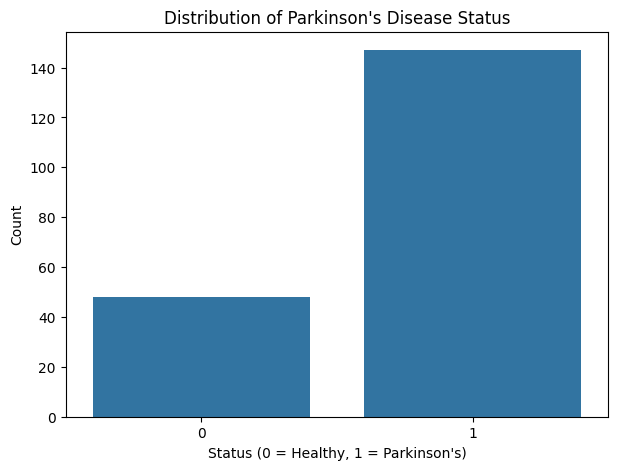

In [13]:
display(df["status"].value_counts().sort_index())
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="status")
plt.title("Distribution of Parkinson's Disease Status")
plt.xlabel("Status (0 = Healthy, 1 = Parkinson's)")
plt.ylabel("Count")
plt.show()


## 🔎 Target Distribution Insight
- Examine whether one class occurs substantially more often than the other.
- If the Parkinson's class is the majority, accuracy alone can be misleading because a model may achieve high accuracy by favoring the majority class.
- Precision, recall, F1-score, and Kappa should therefore be considered.

In [14]:
# Display the dependent variable
# status - health status of the subject (one) - Parkinson's, (zero) – healthy

print (df['status'])

0      1
1      1
2      1
3      1
4      1
      ..
190    0
191    0
192    0
193    0
194    0
Name: status, Length: 195, dtype: int64


# 3. Exploratory Data Analysis (EDA)

### 🔎 Observations & Insights from EDA
EDA helps understand class distribution, feature behaviour, and possible differences between healthy and Parkinson's observations. The dataset contains multiple types of voice measurements, including frequency, jitter, shimmer, noise-related, and nonlinear features.

#### Visualization insight:
Differences between feature distributions across status classes may indicate useful predictive information. However, visible differences represent associations within this dataset and should not be interpreted as causal relationships.

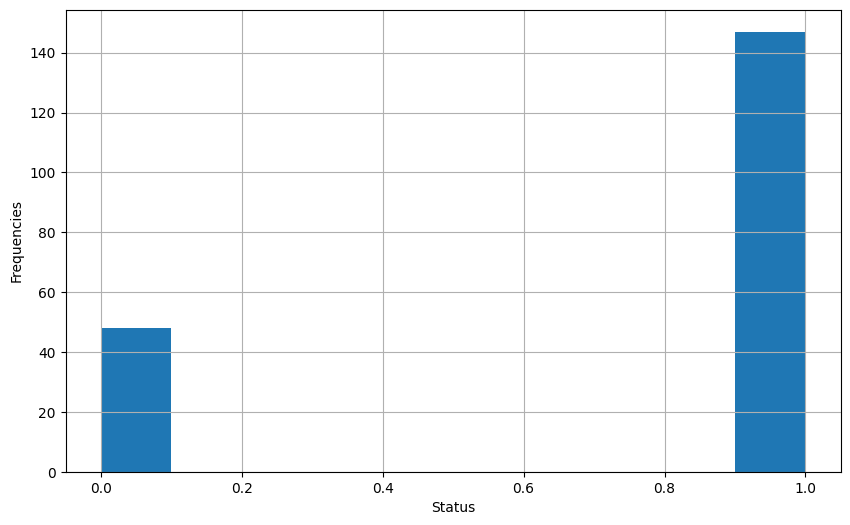

In [15]:
# Create Histogram with Status column
# The dataset has high number of patients effected with Parkinson's disease.
plt.figure(figsize=(10, 6))
df.status.hist()
plt.xlabel('Status')
plt.ylabel('Frequencies')
plt.plot()
plt.show()


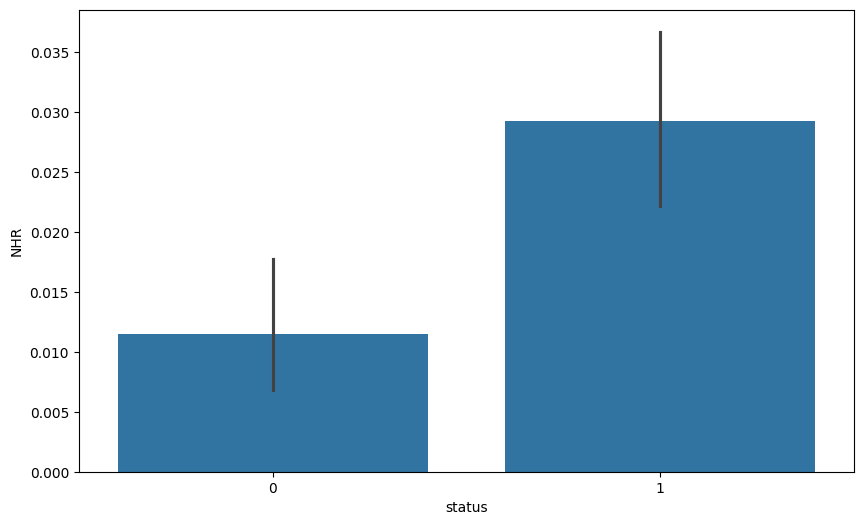

In [16]:
# Create Bar graph- X-Axis Status, Y- Axis NHR
'''
The patients affected with Parkinson's disease have high NHR which is the measure of the ratio of noise to tonal components in the voice.
'''
plt.figure(figsize=(10, 6))
sns.barplot(x="status",y="NHR",data=df);
plt.show()


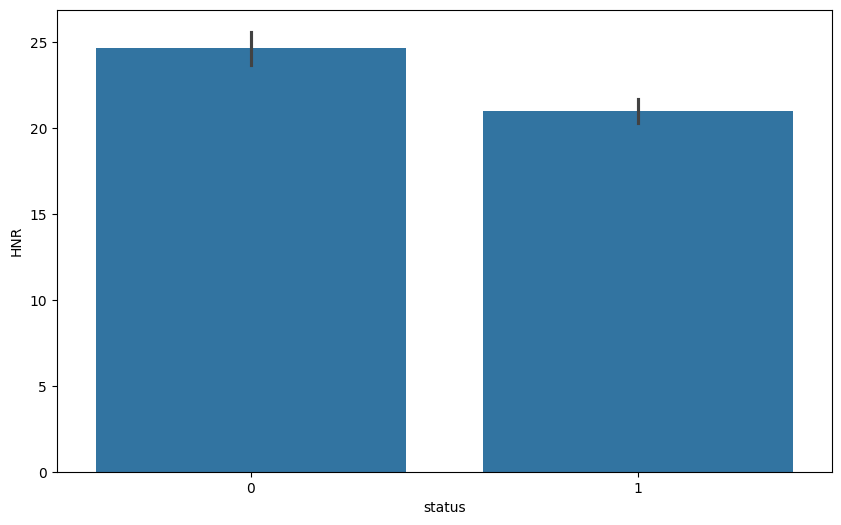

In [17]:
# Create Bar graph- X-Axis Status, Y- Axis HNR
'''
The patients affected with Parkinson's disease have high HNR
that is the measure of the ratio of noise to tonal components in the voice.
'''
plt.figure(figsize=(10, 6))
sns.barplot(x="status",y="HNR",data=df);
plt.show()



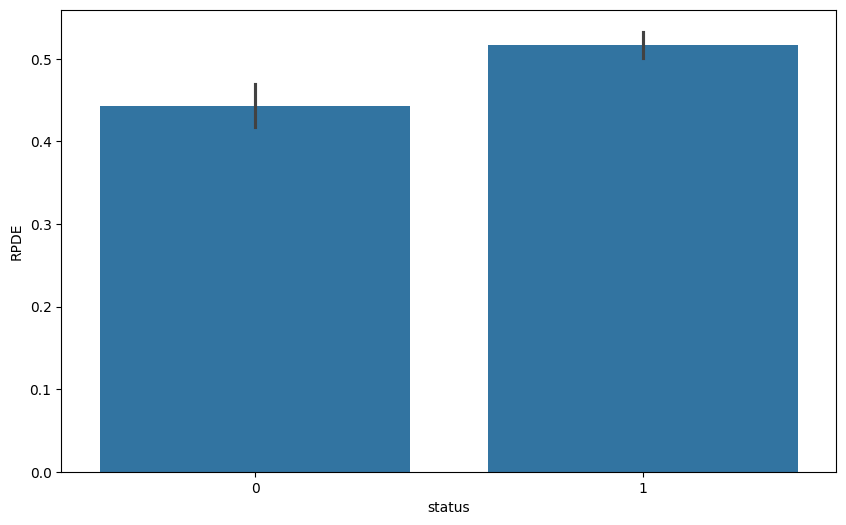

In [18]:
# Create Bar graph- X-Axis Status, Y- Axis RPDE
'''
The nonlinear dynamical complexity measure RPDE is high in the patients affected with Parkinson's disease.
'''
plt.figure(figsize=(10, 6))
sns.barplot(x="status",y="RPDE",data=df);
plt.show()



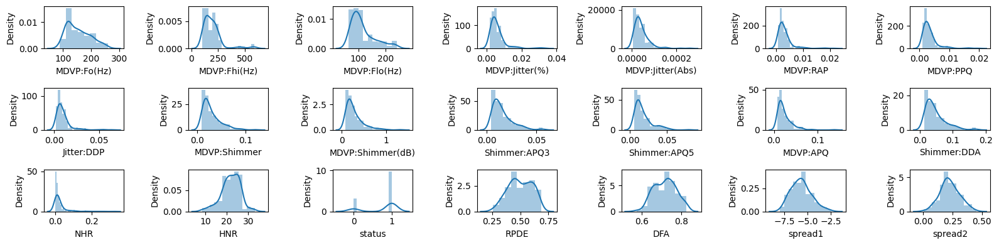

In [19]:
# Create Distribution plot – This used to check skewness in data
import warnings
warnings.filterwarnings('ignore')
rows=3
cols=7
fig, ax=plt.subplots(nrows=rows,ncols=cols,figsize=(16,4))
col=df.columns
index=1
for i in range(rows):
      for j in range(cols):
        sns.distplot(df[col[index]],ax=ax[i][j])
        index=index+1

plt.tight_layout()
plt.show()



### 🔎 Distribution Insight
The feature distributions should be inspected for skewness, different numerical scales, and possible extreme values. Non-normal feature shapes may influence some algorithms, while tree-based models are generally less sensitive to feature scaling and distributional assumptions.

In [20]:
#Display the top 3 records
display (df.head(3))


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634


In [21]:
# Display Co relation Matrix
#Excelue the First Column Name
dfc=df.iloc[:,1:]
display (dfc)


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,174.188,230.978,94.261,0.00459,0.00003,0.00263,0.00259,0.00790,0.04087,0.405,...,0.07008,0.02764,19.517,0,0.448439,0.657899,-6.538586,0.121952,2.657476,0.133050
191,209.516,253.017,89.488,0.00564,0.00003,0.00331,0.00292,0.00994,0.02751,0.263,...,0.04812,0.01810,19.147,0,0.431674,0.683244,-6.195325,0.129303,2.784312,0.168895
192,174.688,240.005,74.287,0.01360,0.00008,0.00624,0.00564,0.01873,0.02308,0.256,...,0.03804,0.10715,17.883,0,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728
193,198.764,396.961,74.904,0.00740,0.00004,0.00370,0.00390,0.01109,0.02296,0.241,...,0.03794,0.07223,19.020,0,0.451221,0.643956,-6.744577,0.207454,2.138608,0.123306


In [22]:
# Remove the column status, since it is the dependent variable
dfc = dfc.drop (['status'], axis =1)
corr = dfc.corr()
display (corr)


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
MDVP:Fo(Hz),1.000000,0.400985,0.596546,-0.118003,-0.382027,-0.076194,-0.112165,-0.076213,-0.098374,-0.073742,...,-0.077774,-0.094732,-0.021981,0.059144,-0.383894,-0.446013,-0.413738,-0.249450,0.177980,-0.372356
MDVP:Fhi(Hz),0.400985,1.000000,0.084951,0.102086,-0.029198,0.097177,0.091126,0.097150,0.002281,0.043465,...,0.004937,-0.003733,0.163766,-0.024893,-0.112404,-0.343097,-0.076658,-0.002954,0.176323,-0.069543
MDVP:Flo(Hz),0.596546,0.084951,1.000000,-0.139919,-0.277815,-0.100519,-0.095828,-0.100488,-0.144543,-0.119089,...,-0.107293,-0.150737,-0.108670,0.210851,-0.400143,-0.050406,-0.394857,-0.243829,-0.100629,-0.340071
MDVP:Jitter(%),-0.118003,0.102086,-0.139919,1.000000,0.935714,0.990276,0.974256,0.990276,0.769063,0.804289,...,0.758255,0.746635,0.906959,-0.728165,0.360673,0.098572,0.693577,0.385123,0.433434,0.721543
MDVP:Jitter(Abs),-0.382027,-0.029198,-0.277815,0.935714,1.000000,0.922911,0.897778,0.922913,0.703322,0.716601,...,0.648793,0.697170,0.834972,-0.656810,0.441839,0.175036,0.735779,0.388543,0.310694,0.748162
MDVP:RAP,-0.076194,0.097177,-0.100519,0.990276,0.922911,1.000000,0.957317,1.000000,0.759581,0.790652,...,0.737455,0.744919,0.919521,-0.721543,0.342140,0.064083,0.648328,0.324407,0.426605,0.670999
MDVP:PPQ,-0.112165,0.091126,-0.095828,0.974256,0.897778,0.957317,1.000000,0.957319,0.797826,0.839239,...,0.804139,0.763592,0.844604,-0.731510,0.333274,0.196301,0.716489,0.407605,0.412524,0.769647
Jitter:DDP,-0.076213,0.097150,-0.100488,0.990276,0.922913,1.000000,0.957319,1.000000,0.759555,0.790621,...,0.737439,0.744901,0.919548,-0.721494,0.342079,0.064026,0.648328,0.324377,0.426556,0.671005
MDVP:Shimmer,-0.098374,0.002281,-0.144543,0.769063,0.703322,0.759581,0.797826,0.759555,1.000000,0.987258,...,0.950083,0.987626,0.722194,-0.835271,0.447424,0.159954,0.654734,0.452025,0.507088,0.693771
MDVP:Shimmer(dB),-0.073742,0.043465,-0.119089,0.804289,0.716601,0.790652,0.839239,0.790621,0.987258,1.000000,...,0.960977,0.963202,0.744477,-0.827805,0.410684,0.165157,0.652547,0.454314,0.512233,0.695058


## 4. Correlation Analysis

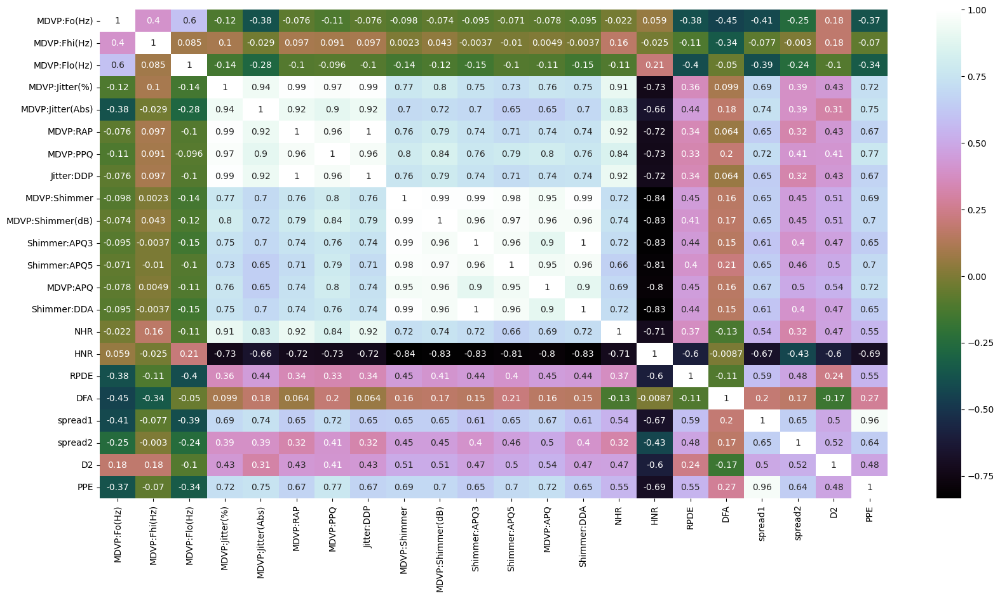

In [23]:
# Display Heat Map
from matplotlib.pylab import rcParams
rcParams['figure.figsize'] = 20,10

sns.heatmap(corr, xticklabels=corr.columns, yticklabels=corr.columns, cmap='cubehelix',annot = True)
plt.show()


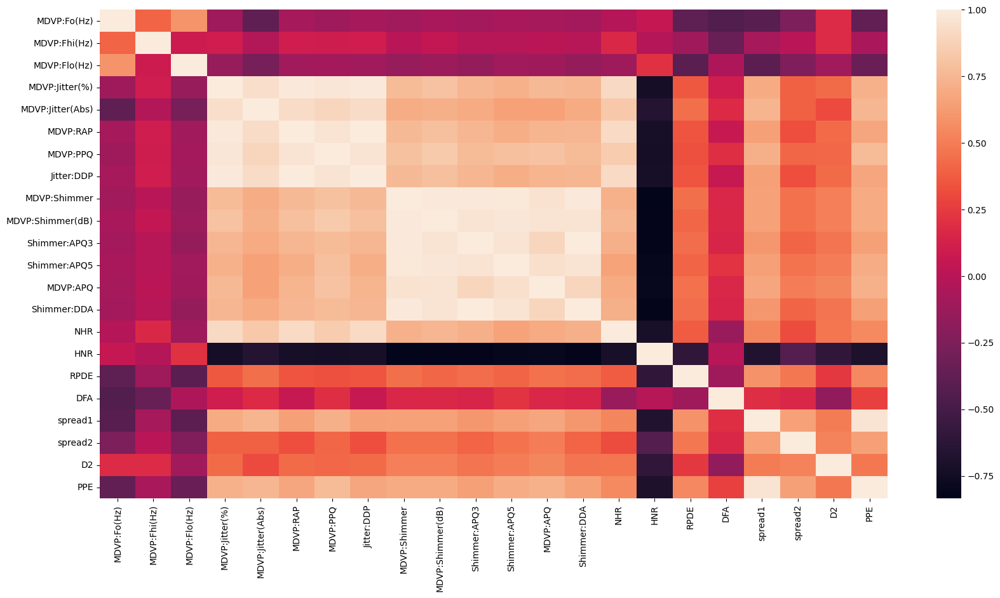

In [24]:
# Heatmap with Default Parameters
from matplotlib.pylab import rcParams
rcParams['figure.figsize'] = 20,10
sns.heatmap(corr)
plt.show()


In [25]:
df.drop(['name'], axis=1, inplace=True, errors='ignore')
display(df)

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,174.188,230.978,94.261,0.00459,0.00003,0.00263,0.00259,0.00790,0.04087,0.405,...,0.07008,0.02764,19.517,0,0.448439,0.657899,-6.538586,0.121952,2.657476,0.133050
191,209.516,253.017,89.488,0.00564,0.00003,0.00331,0.00292,0.00994,0.02751,0.263,...,0.04812,0.01810,19.147,0,0.431674,0.683244,-6.195325,0.129303,2.784312,0.168895
192,174.688,240.005,74.287,0.01360,0.00008,0.00624,0.00564,0.01873,0.02308,0.256,...,0.03804,0.10715,17.883,0,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728
193,198.764,396.961,74.904,0.00740,0.00004,0.00370,0.00390,0.01109,0.02296,0.241,...,0.03794,0.07223,19.020,0,0.451221,0.643956,-6.744577,0.207454,2.138608,0.123306


# 5. Data Preparation

## 🔎 Data Preparation Insights
The name column is correctly excluded because it is an identifier rather than a biomedical measurement. The remaining features form the predictor matrix X, while status forms the target vector y.

This separation creates a standard supervised binary classification problem:

- 0 → Healthy
- 1 → Parkinson's disease

In [26]:
# Spitting the dataset into x and y
# Create X
X=df.drop(labels=['status'],axis=1)
display (X.head())




,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [27]:
# Create  – Y
Y=df['status']
display (Y.head())


0    1
1    1
2    1
3    1
4    1
Name: status, dtype: int64

## 🔎 Train-Test Split

In [28]:
#Splitting the data into x_train, y_train, x_test, y_test

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=40)
print (X.shape,Y.shape)
print(X_train.shape,X_test.shape,Y_train.shape,Y_test.shape)

(195, 22) (195,)
(156, 22) (39, 22) (156,) (39,)


## 6. Model Training and Evaluation
The project evaluates:

- Logistic Regression
- Random Forest
- Decision Tree
- Gaussian Naive Bayes
- K-Nearest Neighbors
- Support Vector Machine


In [29]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score

RANDOM_STATE = 42 # Redefine for robustness if kernel state is inconsistent

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Gaussian Naive Bayes": GaussianNB(),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(weights="distance"))
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", random_state=RANDOM_STATE))
    ])
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, Y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    fitted_models[name] = model

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(Y_train, train_pred),
        "Test Accuracy": accuracy_score(Y_test, test_pred),
        "Precision": precision_score(Y_test, test_pred, zero_division=0),
        "Recall": recall_score(Y_test, test_pred, zero_division=0),
        "F1 Score": f1_score(Y_test, test_pred, zero_division=0),
        "Kappa Score": cohen_kappa_score(Y_test, test_pred),
        "Wrong Predictions": int((Y_test != test_pred).sum())
    })

results_df = pd.DataFrame(results).sort_values(
    by=["Test Accuracy", "F1 Score"], ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,Kappa Score,Wrong Predictions
0,Support Vector Machine,0.916667,0.923077,0.911765,1.000000,0.953846,0.725995,3
1,K-Nearest Neighbors,1.000000,0.923077,0.937500,0.967742,0.952381,0.752643,3
2,Decision Tree,1.000000,0.923077,1.000000,0.903226,0.949153,0.792920,3
3,Random Forest,1.000000,0.871795,0.906250,0.935484,0.920635,0.587738,5
4,Logistic Regression,0.878205,0.846154,0.903226,0.903226,0.903226,0.528226,6
5,Gaussian Naive Bayes,0.730769,0.692308,1.000000,0.612903,0.760000,0.393782,12


In [30]:
# 7. Detailed Evaluation of Each Model

# **7. Detailed Evaluation of Each Model**

Logistic Regression
Test Accuracy: 0.8462
Kappa Score: 0.5282

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.62      0.62         8
           1       0.90      0.90      0.90        31

    accuracy                           0.85        39
   macro avg       0.76      0.76      0.76        39
weighted avg       0.85      0.85      0.85        39



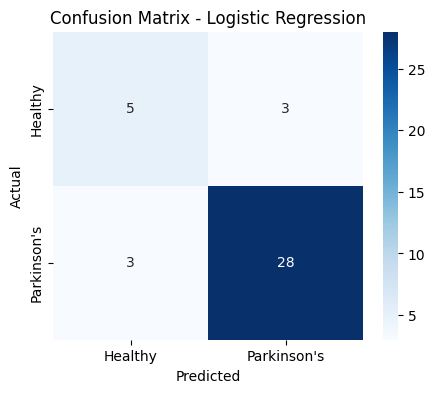

Random Forest
Test Accuracy: 0.8718
Kappa Score: 0.5877

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.62      0.67         8
           1       0.91      0.94      0.92        31

    accuracy                           0.87        39
   macro avg       0.81      0.78      0.79        39
weighted avg       0.87      0.87      0.87        39



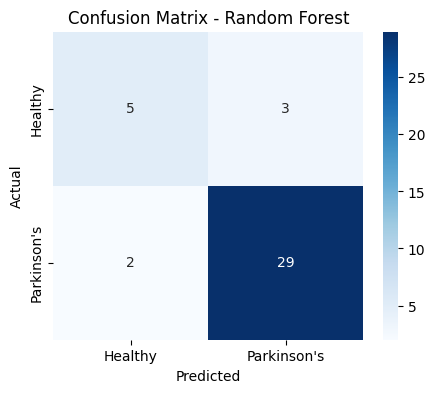

Decision Tree
Test Accuracy: 0.9231
Kappa Score: 0.7929

Classification Report:
              precision    recall  f1-score   support

           0       0.73      1.00      0.84         8
           1       1.00      0.90      0.95        31

    accuracy                           0.92        39
   macro avg       0.86      0.95      0.90        39
weighted avg       0.94      0.92      0.93        39



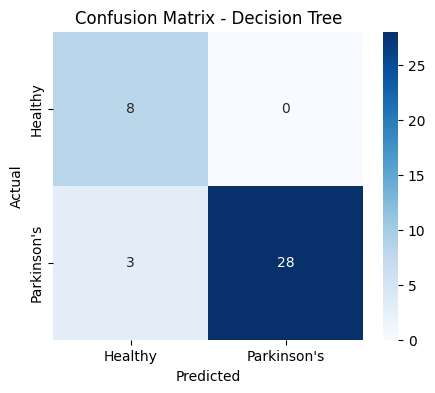

Gaussian Naive Bayes
Test Accuracy: 0.6923
Kappa Score: 0.3938

Classification Report:
              precision    recall  f1-score   support

           0       0.40      1.00      0.57         8
           1       1.00      0.61      0.76        31

    accuracy                           0.69        39
   macro avg       0.70      0.81      0.67        39
weighted avg       0.88      0.69      0.72        39



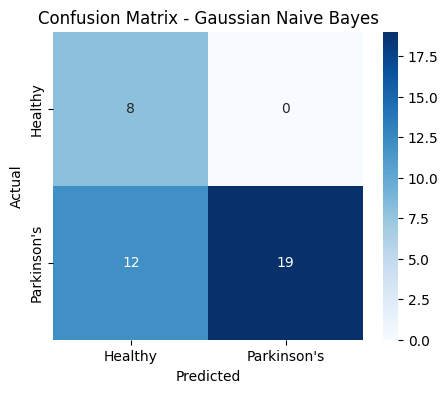

K-Nearest Neighbors
Test Accuracy: 0.9231
Kappa Score: 0.7526

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.75      0.80         8
           1       0.94      0.97      0.95        31

    accuracy                           0.92        39
   macro avg       0.90      0.86      0.88        39
weighted avg       0.92      0.92      0.92        39



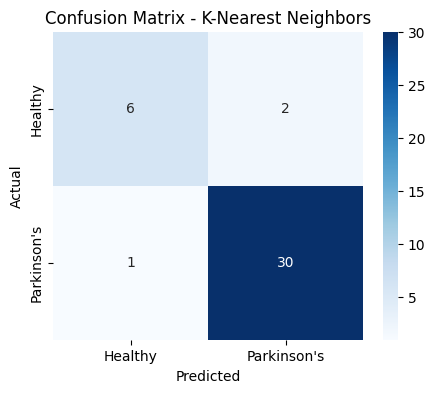

Support Vector Machine
Test Accuracy: 0.9231
Kappa Score: 0.726

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.62      0.77         8
           1       0.91      1.00      0.95        31

    accuracy                           0.92        39
   macro avg       0.96      0.81      0.86        39
weighted avg       0.93      0.92      0.92        39



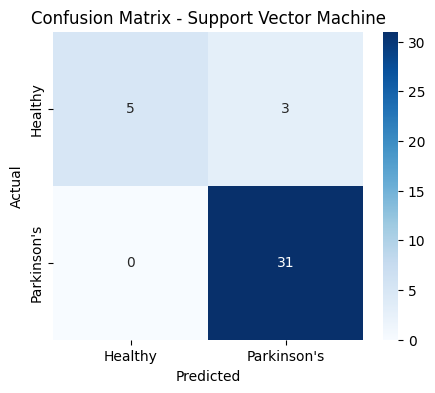

In [31]:
for name, model in fitted_models.items():
    pred = model.predict(X_test)
    print("=" * 80)
    print(name)
    print("=" * 80)
    print("Test Accuracy:", round(accuracy_score(Y_test, pred), 4))
    print("Kappa Score:", round(cohen_kappa_score(Y_test, pred), 4))
    print("\nClassification Report:")
    print(classification_report(Y_test, pred, zero_division=0))

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(Y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Healthy", "Parkinson's"],
                yticklabels=["Healthy", "Parkinson's"])
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [32]:
# Create a Logistic Regression Model
log_reg = LogisticRegression().fit(X_train, Y_train)
#predict on train
train_preds = log_reg.predict(X_train)
#accuracy on train
print("Model accuracy on train is: ", accuracy_score(Y_train, train_preds))



Model accuracy on train is:  0.8717948717948718


In [33]:
#predict on test
test_preds = log_reg.predict(X_test)
#accuracy on test
print("Model accuracy on test is: ", accuracy_score(Y_test, test_preds))
print('-'*50)



Model accuracy on test is:  0.8461538461538461
--------------------------------------------------


In [34]:
#Confusion matrix
print("confusion_matrix train is:\n ", confusion_matrix(Y_train, train_preds))
print("confusion_matrix test is:\n ", confusion_matrix(Y_test, test_preds))
print('\nClassification Report Train is ')
print(classification_report (Y_train, train_preds))
print('\nClassification Report Test is ')
print(classification_report (Y_test, test_preds))




confusion_matrix train is:
  [[ 25  15]
 [  5 111]]
confusion_matrix test is:
  [[ 5  3]
 [ 3 28]]

Classification Report Train is 
              precision    recall  f1-score   support

           0       0.83      0.62      0.71        40
           1       0.88      0.96      0.92       116

    accuracy                           0.87       156
   macro avg       0.86      0.79      0.82       156
weighted avg       0.87      0.87      0.87       156


Classification Report Test is 
              precision    recall  f1-score   support

           0       0.62      0.62      0.62         8
           1       0.90      0.90      0.90        31

    accuracy                           0.85        39
   macro avg       0.76      0.76      0.76        39
weighted avg       0.85      0.85      0.85        39



In [35]:
# Create Random Forest Model

RF=RandomForestClassifier().fit(X_train,Y_train)
#predict on train
train_preds2 = RF.predict(X_train)
#accuracy on train
print("Model accuracy on train is: ", accuracy_score(Y_train, train_preds2))



Model accuracy on train is:  1.0


In [36]:
#predict on test
test_preds2 = RF.predict(X_test)
#accuracy on test
print("Model accuracy on test is: ", accuracy_score(Y_test, test_preds2))




Model accuracy on test is:  0.8717948717948718


In [37]:
#Confusion matrix
print("confusion_matrix train is:\n ", confusion_matrix(Y_train, train_preds2))
print("confusion_matrix test is:\n ", confusion_matrix(Y_test, test_preds2))
print('\nClassification Report Train is ')
print(classification_report (Y_train, train_preds2))
print('\nClassification Report Test is ')
print(classification_report (Y_test, test_preds2))

confusion_matrix train is:
  [[ 40   0]
 [  0 116]]
confusion_matrix test is:
  [[ 5  3]
 [ 2 29]]

Classification Report Train is 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00       116

    accuracy                           1.00       156
   macro avg       1.00      1.00      1.00       156
weighted avg       1.00      1.00      1.00       156


Classification Report Test is 
              precision    recall  f1-score   support

           0       0.71      0.62      0.67         8
           1       0.91      0.94      0.92        31

    accuracy                           0.87        39
   macro avg       0.81      0.78      0.79        39
weighted avg       0.87      0.87      0.87        39



In [38]:
# Wrong Predictions made
print((Y_test !=test_preds2).sum(),'/',((Y_test == test_preds2).sum()+(Y_test != test_preds2).sum()))





5 / 39


In [39]:
# Kappa Score
print('KappaScore is: ', metrics.cohen_kappa_score(Y_test,test_preds2))

KappaScore is:  0.587737843551797


In [40]:
# Display the test and Predicted Values
ddf=pd.DataFrame(data=[test_preds2,Y_test])
display (ddf)



,0,1,2,3,4,5,6,7,8,9,...,29,30,31,32,33,34,35,36,37,38
0,1,1,1,0,1,1,1,1,1,1,...,1,0,0,0,1,1,1,1,0,1
1,1,1,1,0,1,0,1,1,1,0,...,1,0,0,0,1,1,1,1,1,1


In [41]:
#Transpose and display

display (ddf.T)



,0,1
0,1,1
1,1,1
2,1,1
3,0,0
4,1,1
5,1,0
6,1,1
7,1,1
8,1,1
9,1,0


In [42]:
# Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
#fit the model on train data
DT = DecisionTreeClassifier().fit(X,Y)

#predict on train
train_preds3 = DT.predict(X_train)
#accuracy on train
print("Model accuracy on train is: ", accuracy_score(Y_train, train_preds3))



Model accuracy on train is:  1.0


In [43]:
#predict on test
test_preds3 = DT.predict(X_test)
#accuracy on test
print("Model accuracy on test is: ", accuracy_score(Y_test, test_preds3))
print('-'*50)
#Confusion matrix
print("confusion_matrix train is:\n ", confusion_matrix(Y_train, train_preds3))
print("confusion_matrix test is: \n", confusion_matrix(Y_test, test_preds3))
print('Wrong predictions out of total')
print('-'*50)
print('\nClassification Report Train is ')
print(classification_report (Y_train, train_preds3))
print('\nClassification Report Test is ')
print(classification_report (Y_test, test_preds3))


Model accuracy on test is:  1.0
--------------------------------------------------
confusion_matrix train is:
  [[ 40   0]
 [  0 116]]
confusion_matrix test is: 
 [[ 8  0]
 [ 0 31]]
Wrong predictions out of total
--------------------------------------------------

Classification Report Train is 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00       116

    accuracy                           1.00       156
   macro avg       1.00      1.00      1.00       156
weighted avg       1.00      1.00      1.00       156


Classification Report Test is 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        31

    accuracy                           1.00        39
   macro avg       1.00      1.00      1.00        39
weighted avg       1.00      1.00      1.00        39



In [44]:
# Wrong Prediction and Kappa Score

# Wrong Predictions made.
print((Y_test !=test_preds3).sum(),'/',((Y_test == test_preds3).sum()+(Y_test != test_preds3).sum()))
print('-'*50)

# Kappa Score
print('KappaScore is: ', metrics.cohen_kappa_score(Y_test,test_preds3))


0 / 39
--------------------------------------------------
KappaScore is:  1.0


In [45]:
# Naïve Bayce  algorithm

from sklearn.naive_bayes import GaussianNB
#fit the model on train data
NB=GaussianNB()
NB.fit(X_train,Y_train)
#predict on train
train_preds4 = NB.predict(X_train)
#accuracy on train
print("Model accuracy on train is: ", accuracy_score(Y_train, train_preds4))

#predict on test
test_preds4 = NB.predict(X_test)
#accuracy on test
print("Model accuracy on test is: ", accuracy_score(Y_test, test_preds4))
print('-'*50)
#Confusion matrix
print("confusion_matrix train is: \n", confusion_matrix(Y_train, train_preds4))
print("confusion_matrix test is:\n ", confusion_matrix(Y_test, test_preds4))
print('Wrong predictions out of total')
print('-'*50)
print('\nClassification Report Train is ')
print(classification_report (Y_train, train_preds4))
print('\nClassification Report Test is ')
print(classification_report (Y_test, test_preds4))



Model accuracy on train is:  0.7307692307692307
Model accuracy on test is:  0.6923076923076923
--------------------------------------------------
confusion_matrix train is: 
 [[38  2]
 [40 76]]
confusion_matrix test is:
  [[ 8  0]
 [12 19]]
Wrong predictions out of total
--------------------------------------------------

Classification Report Train is 
              precision    recall  f1-score   support

           0       0.49      0.95      0.64        40
           1       0.97      0.66      0.78       116

    accuracy                           0.73       156
   macro avg       0.73      0.80      0.71       156
weighted avg       0.85      0.73      0.75       156


Classification Report Test is 
              precision    recall  f1-score   support

           0       0.40      1.00      0.57         8
           1       1.00      0.61      0.76        31

    accuracy                           0.69        39
   macro avg       0.70      0.81      0.67        39
weighted avg 

In [46]:
# Wrong Prediction and Kappa Score
# Wrong Predictions made.

print((Y_test !=test_preds4).sum(),'/',((Y_test == test_preds4).sum()+(Y_test != test_preds4).sum()))
print('-'*50)

# Kappa Score
print('KappaScore is: ', metrics.cohen_kappa_score(Y_test,test_preds4))


12 / 39
--------------------------------------------------
KappaScore is:  0.3937823834196892


In [47]:
# K Neighbours Classifier

from sklearn.neighbors import KNeighborsClassifier
#fit the model on train data
# Using the parameter weights='distance'  to fix the error 'Flags' object has no attribute 'c_contiguous'
KNN = KNeighborsClassifier(weights='distance').fit(X_train,Y_train)
#predict on train
train_preds5 = KNN.predict(X_train)
#accuracy on train
print("Model accuracy on train is: ", accuracy_score(Y_train, train_preds5))

#predict on test
test_preds5 = KNN.predict(X_test)
#accuracy on test
print("Model accuracy on test is: ", accuracy_score(Y_test, test_preds5))
print('-'*50)
#Confusion matrix
print("confusion_matrix train is:\n ", confusion_matrix(Y_train, train_preds5))
print("confusion_matrix test is:\n ", confusion_matrix(Y_test, test_preds5))
print('Wrong predictions out of total')
print('-'*50)
print('\nClassification Report Train is ')
print(classification_report (Y_train, train_preds5))
print('\nClassification Report Test is ')
print(classification_report (Y_test, test_preds5))


Model accuracy on train is:  1.0
Model accuracy on test is:  0.8461538461538461
--------------------------------------------------
confusion_matrix train is:
  [[ 40   0]
 [  0 116]]
confusion_matrix test is:
  [[ 4  4]
 [ 2 29]]
Wrong predictions out of total
--------------------------------------------------

Classification Report Train is 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00       116

    accuracy                           1.00       156
   macro avg       1.00      1.00      1.00       156
weighted avg       1.00      1.00      1.00       156


Classification Report Test is 
              precision    recall  f1-score   support

           0       0.67      0.50      0.57         8
           1       0.88      0.94      0.91        31

    accuracy                           0.85        39
   macro avg       0.77      0.72      0.74        39
weighted avg       0.84 

In [48]:
#  Wrong Prediction and Kappa Score
# Wrong Predictions made.
print((Y_test !=test_preds5).sum(),'/',((Y_test == test_preds5).sum()+(Y_test != test_preds5).sum()))

print('-'*50)
# Kappa Score
print('KappaScore is: ', metrics.cohen_kappa_score(Y_test,test_preds5))


6 / 39
--------------------------------------------------
KappaScore is:  0.48


In [49]:
# Support Vector Machine
from sklearn.svm import SVC
#fit the model on train data
SVM = SVC(kernel='linear')
SVM.fit(X_train, Y_train)

#predict on train
train_preds6 = SVM.predict(X_train)
#accuracy on train
print("Model accuracy on train is: ", accuracy_score(Y_train, train_preds6))

#predict on test
test_preds6 = SVM.predict(X_test)
#accuracy on test
print("Model accuracy on test is: ", accuracy_score(Y_test, test_preds6))
print('-'*50)
#Confusion matrix
print("confusion_matrix train is: \n", confusion_matrix(Y_train, train_preds6))
print("confusion_matrix test is:\n ", confusion_matrix(Y_test, test_preds6))
print('Wrong predictions out of total')
print('-'*50)

print("recall", metrics.recall_score(Y_test, test_preds6))
print('-'*50)
print('\nClassification Report Train is ')
print(classification_report (Y_train, train_preds6))
print('\nClassification Report Test is ')
print(classification_report (Y_test, test_preds6))


Model accuracy on train is:  0.8782051282051282
Model accuracy on test is:  0.8974358974358975
--------------------------------------------------
confusion_matrix train is: 
 [[ 23  17]
 [  2 114]]
confusion_matrix test is:
  [[ 5  3]
 [ 1 30]]
Wrong predictions out of total
--------------------------------------------------
recall 0.967741935483871
--------------------------------------------------

Classification Report Train is 
              precision    recall  f1-score   support

           0       0.92      0.57      0.71        40
           1       0.87      0.98      0.92       116

    accuracy                           0.88       156
   macro avg       0.90      0.78      0.82       156
weighted avg       0.88      0.88      0.87       156


Classification Report Test is 
              precision    recall  f1-score   support

           0       0.83      0.62      0.71         8
           1       0.91      0.97      0.94        31

    accuracy                           0.

In [50]:
# Wrong Prediction and Kappa Score
# Wrong Predictions made.
print((Y_test !=test_preds6).sum(),'/',((Y_test == test_preds6).sum()+(Y_test != test_preds6).sum()))
print('-'*50)
# Kappa Score
print('KappaScore is: ', metrics.cohen_kappa_score(Y_test,test_preds6))


4 / 39
--------------------------------------------------
KappaScore is:  0.6533333333333333


# **8. Model Comparison**

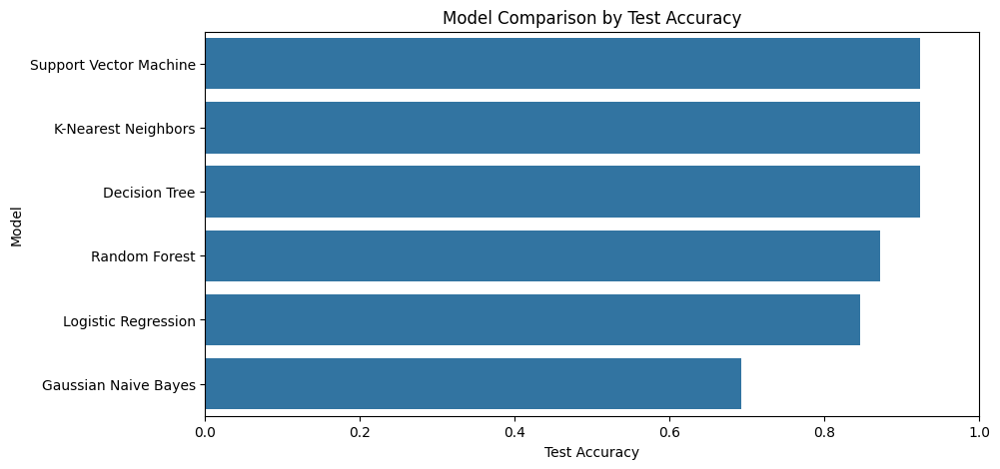

Best model based on Test Accuracy:


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,Kappa Score,Wrong Predictions
0,Support Vector Machine,0.916667,0.923077,0.911765,1.0,0.953846,0.725995,3


In [51]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Test Accuracy", y="Model")
plt.title("Model Comparison by Test Accuracy")
plt.xlim(0, 1)
plt.show()

print("Best model based on Test Accuracy:")
display(results_df.head(1))

# **9. Best Model Selection and Prediction Results**

In [52]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

prediction_results = pd.DataFrame({
    "Actual Status": Y_test.reset_index(drop=True),
    "Predicted Status": best_predictions
})

display(prediction_results.head(20))
print("Selected model:", best_model_name)


,Actual Status,Predicted Status
0,1,1
1,1,1
2,1,1
3,0,0
4,1,1
5,0,1
6,1,1
7,1,1
8,1,1
9,0,0


Selected model: Support Vector Machine


# **10. Save the Selected Model**
The trained best model is serialized as a pickle file. The complete preprocessing pipeline is saved together with the model when applicable.

In [53]:
import pickle

# Saving model to disk
pickle.dump(best_model, open('deploy_SVM.pkl','wb')) # Changed best_model to SVM and filename

# Open the Pickle File
model=pickle.load(open('deploy_SVM.pkl','rb')) # Changed filename

# Prediction
print (model.predict (X_test))

[1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1
 1 1]


In [54]:
# Prediction with Pickle File
# Import Libraries
import pandas as pd
import numpy as np
import os
import pickle
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [56]:
# Load Data Set
df=pd.read_csv('parkinsons.data')
display (df)


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,phon_R01_S50_2,174.188,230.978,94.261,0.00459,0.00003,0.00263,0.00259,0.00790,0.04087,...,0.07008,0.02764,19.517,0,0.448439,0.657899,-6.538586,0.121952,2.657476,0.133050
191,phon_R01_S50_3,209.516,253.017,89.488,0.00564,0.00003,0.00331,0.00292,0.00994,0.02751,...,0.04812,0.01810,19.147,0,0.431674,0.683244,-6.195325,0.129303,2.784312,0.168895
192,phon_R01_S50_4,174.688,240.005,74.287,0.01360,0.00008,0.00624,0.00564,0.01873,0.02308,...,0.03804,0.10715,17.883,0,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728
193,phon_R01_S50_5,198.764,396.961,74.904,0.00740,0.00004,0.00370,0.00390,0.01109,0.02296,...,0.03794,0.07223,19.020,0,0.451221,0.643956,-6.744577,0.207454,2.138608,0.123306


In [57]:
X=df.drop(labels=['status','name'],axis=1)
display (X.head())


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [58]:
Y=df['status']
display (Y.head())


0    1
1    1
2    1
3    1
4    1
Name: status, dtype: int64

In [59]:
# Load Pickle File and Prediction with Pickle File

model=pickle.load(open('deploy_SVM.pkl','rb'))
# Prediction
prediction = model.predict (X)
print ( 'Accuracy ',accuracy_score (Y, prediction))
print ()
print ( 'Classification Report')
print (classification_report  (Y,prediction,zero_division=0))
print ( 'Confusion Matrix')
print (confusion_matrix  (Y,prediction))

Accuracy  0.9179487179487179

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.69      0.80        48
           1       0.91      0.99      0.95       147

    accuracy                           0.92       195
   macro avg       0.94      0.84      0.88       195
weighted avg       0.92      0.92      0.91       195

Confusion Matrix
[[ 33  15]
 [  1 146]]


In [60]:
# Display the Result

result = pd.concat ([df['status'],pd.DataFrame (prediction,columns = ['Prediction'])],axis =1)
display (result.head(50))



,status,Prediction
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


# Conclusion

# Data & EDA
- The dataset is small (195 voice recordings, 22 predictor features) with no missing values and no duplicates, so no imputation or deduplication was needed.
- The target is imbalanced: 147 Parkinson's cases (status=1) vs. 48 healthy (status=0) — roughly 75%/25%. This means accuracy alone can be misleading, and precision/recall/F1/Kappa (which the notebook does track) are the more trustworthy metrics.
- EDA showed visible differences between the two groups on voice-quality features such as NHR, HNR, and RPDE, and the correlation heatmap revealed strong multicollinearity among the jitter and shimmer feature families — expected, since they're mathematical variants of the same underlying signal measurement.

# Model Comparison (test set, 39 samples)

- Three models tied on raw test accuracy (92.3%); SVM was selected as the best model (highest F1 and perfect recall on the positive class), though Decision Tree actually had the highest Kappa (0.79 vs 0.73), meaning it agreed with the true labels somewhat more than chance would predict.
- Naive Bayes performed worst (Kappa 0.39 = only "fair" agreement), likely because its independence assumption doesn't hold given the highly correlated voice features.
- Several models (Random Forest, Decision Tree, KNN) hit 100% training accuracy but noticeably lower test accuracy — a classic small-dataset overfitting signal.

# Final Model (deployed SVM) on full data

- Reloading deploy_SVM.pkl and scoring on all 195 records gave 91.8% accuracy, but recall was very asymmetric: 99% recall for Parkinson's (146/147 correct) vs. only 69% recall for Healthy (33/48 correct, 15 misclassified as Parkinson's).
- This is the practical consequence of the class imbalance: the model is much better at catching Parkinson's cases than at correctly clearing healthy patients, which matters clinically (false positives) even though overall accuracy looks strong.

# Key Takeaways / Limitations

- Class imbalance biases every model toward the majority (Parkinson's) class — the "Healthy" class consistently has lower precision/recall across all six models.
- Small sample size (195 rows, 39-row test set) makes single train/test split metrics unstable; results would benefit from stratified k-fold cross-validation rather than one split.
- High feature correlation (jitter/shimmer families) suggests dimensionality reduction or feature selection could simplify the model without losing signal.
- For a production/clinical setting, addressing the imbalance (class weighting, SMOTE, or a decision-threshold adjustment) would likely improve minority-class recall meaningfully, even if it costs a little overall accuracy.